## Ridge regrission LOSO evaluation

In [ ]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False
})

def save_figure(fig, filename):
    fig.savefig(
        FIGURE_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    print(f"Saved: {filename}")

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "monthly_features_qc.csv"

data = pd.read_csv(DATA_PATH)
df = data.loc[data["ELIGIBLE_B_90"] == True].copy()

print("Full dataset:", data.shape)
print("Comparison observations:", len(df))

Full dataset: (2016, 40)
Comparison observations: 1768


In [237]:
LEARNING_RATE, ITERATIONS, LAMBDA = 0.01, 3000, 0.1

def fit_predict_fold(train_df, test_df, features, lambda_=LAMBDA):
    X_train = train_df[features].to_numpy(dtype=float)
    X_test = test_df[features].to_numpy(dtype=float)
    y_train = train_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
    y_test = test_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

    mean, std = fit_standardizer(X_train)
    model = RidgeRegressionGD(
        learning_rate=LEARNING_RATE,
        iterations=ITERATIONS,
        lambda_=lambda_
    )
    X_train_scaled = transform_standardizer(X_train, mean, std)
    X_test_scaled = transform_standardizer(X_test, mean, std)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    return model, y_train, y_test, y_pred

In [240]:
from src.validation import manual_loso
from src.preprocessing import fit_standardizer, transform_standardizer
from src.models.ridge_gd import RidgeRegressionGD

FEATURES_A = [
    "TEMP_MEAN",
    "DEWP_MEAN",
    "WDSP_MEAN",
    "TEMP_MIN_MEAN",
    "TEMP_MAX_MEAN"
]

test_station, train_df, test_df = next(manual_loso(df))

model, y_train, y_test, y_pred = fit_predict_fold(train_df, test_df, FEATURES_A)

print("Held-out station:", test_station)
print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))
print("Initial cost:", model.cost_history[0])
print("Final cost:", model.cost_history[-1])
print("First five predictions:", y_pred[:5])


Held-out station: 41184099999
Training observations: 1471
Testing observations: 297
Initial cost: 243.78120581142815
Final cost: 221.84625545118843
First five predictions: [ 9.21864112  4.86222848  1.58752372  0.96534417 -0.60348812]


Saved: ridge_gd_convergence_fold1


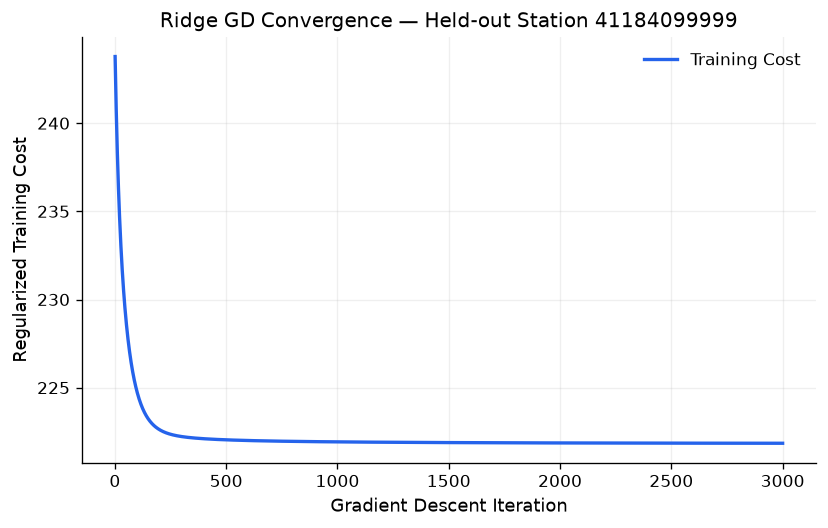

In [173]:
fig, ax = plt.subplots(figsize=(7, 4.5))
iterations = np.arange(1, len(model.cost_history) + 1)

ax.plot(
    iterations,
    model.cost_history,
    color="#2563EB",
    linewidth=2,
    label="Training Cost"
)
ax.set_xlabel("Gradient Descent Iteration")
ax.set_ylabel("Regularized Training Cost")
ax.set_title(
    f"Ridge GD Convergence — Held-out Station {test_station}"
)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "ridge_gd_convergence_fold1")

plt.show()

In [174]:
def calculate_mae(y_true, y_pred):
    absolute_errors = np.abs(y_true - y_pred)
    return np.mean(absolute_errors)


def calculate_rmse(y_true, y_pred):
    squared_errors = (y_true - y_pred) ** 2
    return np.sqrt(np.mean(squared_errors))


mae = calculate_mae(y_test, y_pred)
rmse = calculate_rmse(y_test, y_pred)

print("Held-out station:", test_station)
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


Held-out station: 41184099999
MAE: 9.0291
RMSE: 19.0617


Saved: ridge_gd_actual_vs_predicted_fold1


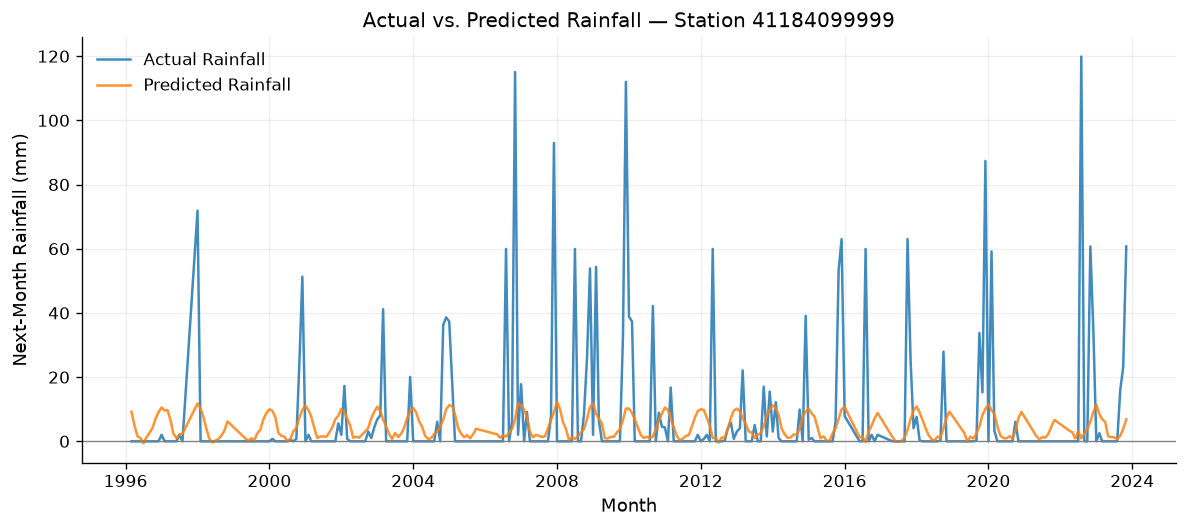

In [175]:
# Figure 2 — Actual vs Predicted Rainfall
plot_df = test_df.copy()

plot_df["ACTUAL"] = y_test
plot_df["PREDICTED"] = y_pred

plot_df["MONTH"] = pd.to_datetime(
    plot_df["MONTH"].astype(str)
)
plot_df = plot_df.sort_values("MONTH")
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    plot_df["MONTH"],
    plot_df["ACTUAL"],
    label="Actual Rainfall",
    linewidth=1.5,
    alpha=0.85
)
ax.plot(
    plot_df["MONTH"],
    plot_df["PREDICTED"],
    label="Predicted Rainfall",
    linewidth=1.5,
    alpha=0.85
)

ax.axhline(0, linewidth=0.8, color="gray")
ax.set_xlabel("Month")
ax.set_ylabel("Next-Month Rainfall (mm)")
ax.set_title(
    f"Actual vs. Predicted Rainfall — Station {test_station}"
)

ax.legend(frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()

save_figure(fig, "ridge_gd_actual_vs_predicted_fold1")
plt.show()


In [245]:
# Full LOSO — Feature Set A (weather only)
fold_results = []

for test_station, train_df, test_df in manual_loso(df):

    model, y_train, y_test, y_pred = fit_predict_fold(train_df, test_df, FEATURES_A)

    mae = calculate_mae(y_test, y_pred)
    rmse = calculate_rmse(y_test, y_pred)

    fold_results.append({
        "STATION": test_station,
        "TRAIN_ROWS": len(train_df),
        "TEST_ROWS": len(test_df),
        "MAE": mae,
        "RMSE": rmse,
        "FINAL_COST": model.cost_history[-1]
    })

results_a = pd.DataFrame(fold_results)
display(results_a)



,STATION,TRAIN_ROWS,TEST_ROWS,MAE,RMSE,FINAL_COST
0,41184099999,1471,297,9.029103,19.061704,221.846255
1,41194099999,1455,313,7.727030,13.620156,240.795908
2,41196099999,1473,295,9.637432,20.005803,217.508411
3,41198099999,1496,272,12.321952,35.571148,139.144541
4,41217099999,1466,302,7.512526,13.580948,240.060540
5,41218099999,1479,289,6.866034,17.122279,227.961338


Saved: ridge_gd_loso_feature_set_a


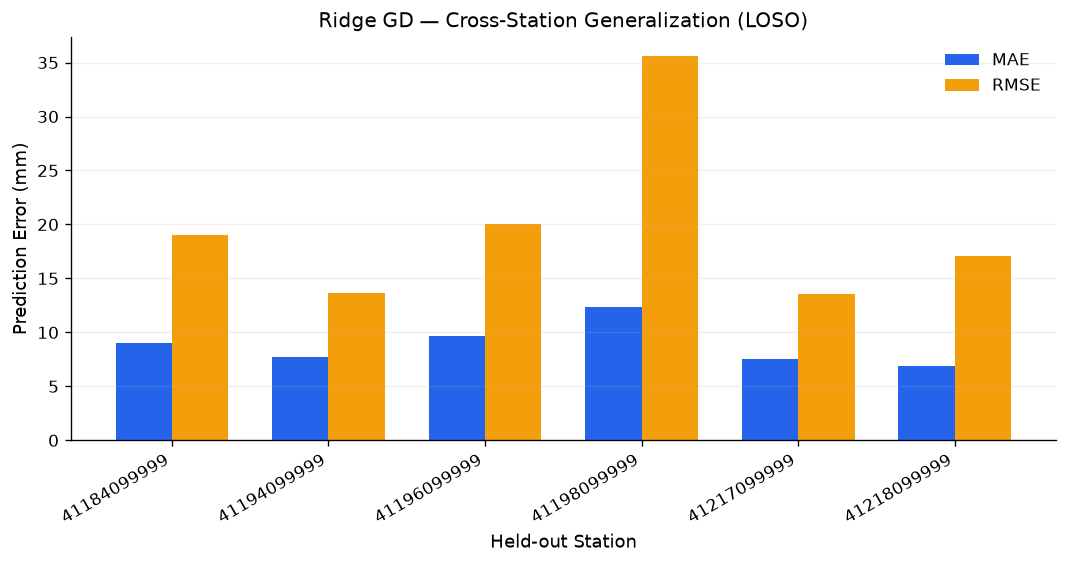

In [246]:
plot_results = results_a.copy()
plot_results["STATION"] = plot_results["STATION"].astype(str)

x = np.arange(len(plot_results))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4.8))

bars_mae = ax.bar(
    x - width / 2,
    plot_results["MAE"],
    width,
    label="MAE",
    color="#2563EB"
)

bars_rmse = ax.bar(
    x + width / 2,
    plot_results["RMSE"],
    width,
    label="RMSE",
    color="#F59E0B"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_results["STATION"], rotation=30, ha="right")
ax.set_ylabel("Prediction Error (mm)")
ax.set_xlabel("Held-out Station")
ax.set_title("Ridge GD — Cross-Station Generalization (LOSO)")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "ridge_gd_loso_feature_set_a")
plt.show()


In [247]:
FEATURES_B = FEATURES_A + [
    'PRCP_LAG_0',
    'PRCP_LAG_1',
    'PRCP_LAG_2',
]

fold_results_b = []

for test_station, train_df, test_df in manual_loso(df):
    
    model, y_train, y_test, y_pred = fit_predict_fold(train_df, test_df, FEATURES_B)

    mae = calculate_mae(y_test, y_pred)
    rmse = calculate_rmse(y_test, y_pred)

    fold_results_b.append({
        "STATION": test_station,
        "TRAIN_ROWS": len(train_df),
        "TEST_ROWS": len(test_df),
        "MAE": mae,
        "RMSE": rmse,
        "FINAL_COST": model.cost_history[-1]
    })

results_b = pd.DataFrame(fold_results_b)
display(results_b)

,STATION,TRAIN_ROWS,TEST_ROWS,MAE,RMSE,FINAL_COST
0,41184099999,1471,297,9.141254,18.991394,220.638621
1,41194099999,1455,313,7.581450,13.634678,239.382852
2,41196099999,1473,295,9.662197,19.939531,216.568595
3,41198099999,1496,272,12.817771,35.945825,137.301285
4,41217099999,1466,302,7.268178,13.562214,238.695156
5,41218099999,1479,289,6.672545,17.066025,226.969846


,STATION,MAE_A,RMSE_A,MAE_B,RMSE_B
0,41184099999,9.029103,19.061704,9.141254,18.991394
1,41194099999,7.727030,13.620156,7.581450,13.634678
2,41196099999,9.637432,20.005803,9.662197,19.939531
3,41198099999,12.321952,35.571148,12.817771,35.945825
4,41217099999,7.512526,13.580948,7.268178,13.562214
5,41218099999,6.866034,17.122279,6.672545,17.066025


Saved: ridge_gd_feature_comparison_mae


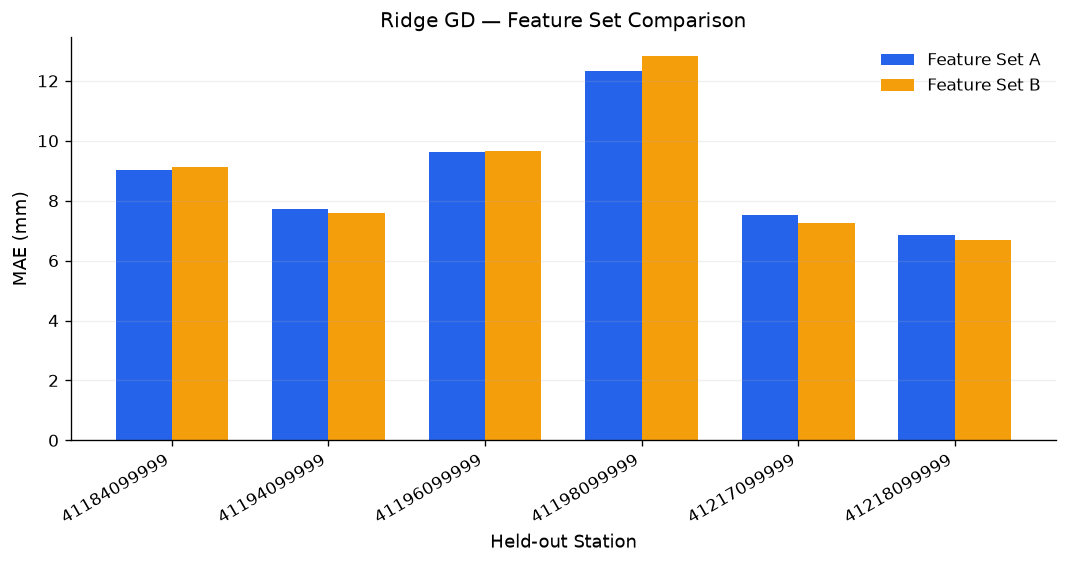

Mean MAE — Set A: 8.849012612510693
Mean MAE — Set B: 8.857232499739034
Mean RMSE — Set A: 19.827006452186478
Mean RMSE — Set B: 19.856610960128993


In [229]:
# Compare Feature Set A and B
comparison_results = results_a[
    ["STATION", "MAE", "RMSE"]
].merge(
    results_b[["STATION", "MAE", "RMSE"]],
    on="STATION",
    suffixes=("_A", "_B"),
    validate="one_to_one"
)

display(comparison_results)

x = np.arange(len(comparison_results))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4.8))

ax.bar(
    x - width / 2,
    comparison_results["MAE_A"],
    width,
    label="Feature Set A",
    color="#2563EB"
)

ax.bar(
    x + width / 2,
    comparison_results["MAE_B"],
    width,
    label="Feature Set B",
    color="#F59E0B"
)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison_results["STATION"].astype(str),
    rotation=30,
    ha="right"
)

ax.set_xlabel("Held-out Station")
ax.set_ylabel("MAE (mm)")
ax.set_title("Ridge GD — Feature Set Comparison")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "ridge_gd_feature_comparison_mae")
plt.show()

print("Mean MAE — Set A:", comparison_results["MAE_A"].mean())
print("Mean MAE — Set B:", comparison_results["MAE_B"].mean())
print("Mean RMSE — Set A:", comparison_results["RMSE_A"].mean())
print("Mean RMSE — Set B:", comparison_results["RMSE_B"].mean())


Under six-fold leave-one-station-out cross-validation, Ridge Regression trained with batch gradient descent achieved a mean station-wise MAE of 8.849 mm and RMSE of 19.827 mm using meteorological features alone. Adding three historical rainfall lags resulted in a marginal increase in mean MAE to 8.857 mm and RMSE to 19.857 mm, indicating no consistent improvement in cross-station predictive performance under the evaluated configuration.

In [ ]:
# Zero-rainfall baseline

baseline_results = []

for test_station, train_df, test_df in manual_loso(df):
    y_test = test_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
    y_pred_baseline = np.zeros(len(y_test))

    baseline_mae = calculate_mae(y_test, y_pred_baseline)
    baseline_rmse = calculate_rmse(y_test, y_pred_baseline)

    baseline_results.append({
        "STATION": test_station,
        "TEST_ROWS": len(test_df),
        "MAE": baseline_mae,
        "RMSE": baseline_rmse
    })

baseline_results_df = pd.DataFrame(baseline_results)
display(baseline_results_df)

print("Mean Zero MAE:", baseline_results_df["MAE"].mean())
print("Mean Zero RMSE:", baseline_results_df["RMSE"].mean())


,STATION,TEST_ROWS,MAE,RMSE
0,41184099999,297,7.673879,20.865247
1,41194099999,313,4.657208,14.718625
2,41196099999,295,7.774122,21.650531
3,41198099999,272,9.001125,36.745573
4,41217099999,302,3.439934,13.768497
5,41218099999,289,3.783633,17.512824


Mean Zero MAE: 6.054983413722706
Mean Zero RMSE: 20.876882774656618


Saved: ridge_gd_vs_zero_baseline_journal


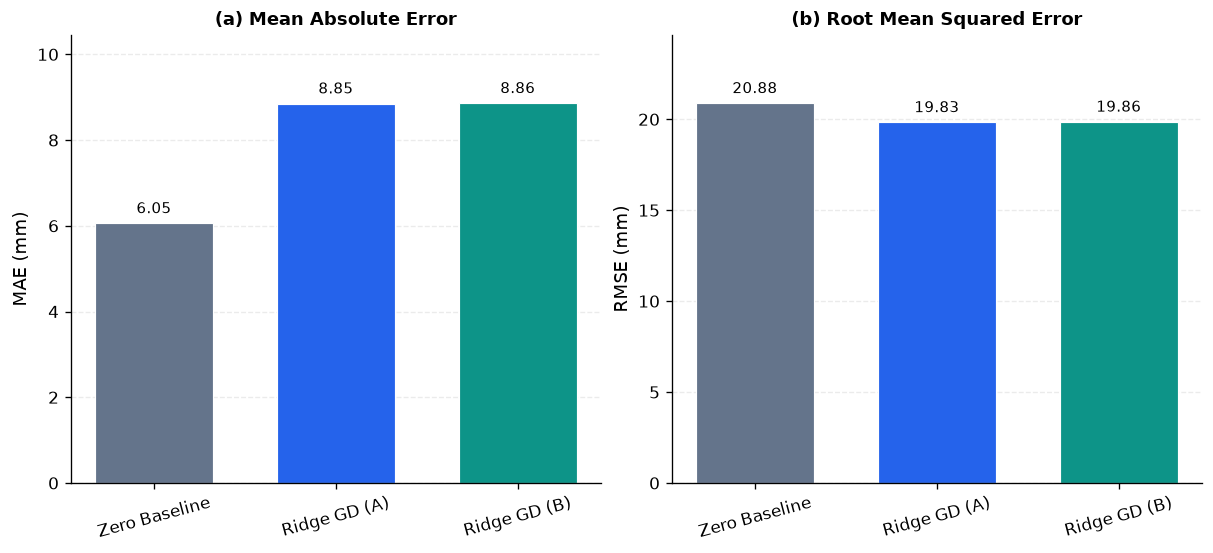

In [230]:
model_names = [
    "Zero Baseline",
    "Ridge GD (A)",
    "Ridge GD (B)"
]

mean_mae = [
    baseline_results_df["MAE"].mean(),
    results_a["MAE"].mean(),
    results_b["MAE"].mean()
]

mean_rmse = [
    baseline_results_df["RMSE"].mean(),
    results_a["RMSE"].mean(),
    results_b["RMSE"].mean()
]
colors = ["#64748B", "#2563EB", "#0D9488"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
metrics = [
    ("(a) Mean Absolute Error", mean_mae, "MAE (mm)"),
    ("(b) Root Mean Squared Error", mean_rmse, "RMSE (mm)")
]

for ax, (title, values, ylabel) in zip(axes, metrics):

    bars = ax.bar(
        model_names,
        values,
        color=colors,
        width=0.65,
        edgecolor="white",
        linewidth=0.7
    )

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.18)

    # Display metric values above bars
    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=4,
        fontsize=9
    )

    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

save_figure(fig, "ridge_gd_vs_zero_baseline_journal")
plt.show()

In [231]:
# Does Ridge Regression perform differently during dry and wet months?

rainfall = df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

dry_count = np.sum(rainfall == 0)
wet_count = np.sum(rainfall > 0)
dry_percentage = (dry_count / len(rainfall)) * 100
wet_percentage = (wet_count / len(rainfall)) * 100

print(f"Dry months: {dry_count} ({dry_percentage:.2f}%)")
print(f"Wet months: {wet_count} ({wet_percentage:.2f}%)")


Dry months: 1193 (67.48%)
Wet months: 575 (32.52%)


In [250]:
predictions_a = []

for test_station, train_df, test_df in manual_loso(df):

    model, y_train, y_test, y_pred = fit_predict_fold(train_df, test_df, FEATURES_A)

    fold_predictions = pd.DataFrame({
        "STATION": test_station,
        "ACTUAL": y_test,
        "PREDICTED": y_pred
    })

    predictions_a.append(fold_predictions)

predictions_a_df = pd.concat(
    predictions_a,
    ignore_index=True
)
display(predictions_a_df.head())

,STATION,ACTUAL,PREDICTED
0,41184099999,0.0,9.218641
1,41184099999,0.0,4.862228
2,41184099999,0.0,1.587524
3,41184099999,0.0,0.965344
4,41184099999,0.0,-0.603488


In [251]:
def generate_loso_predictions(df, features):
    all_predictions = []
    for test_station, train_df, test_df in manual_loso(df):
        X_train = train_df[features].to_numpy(dtype=float)
        X_test = test_df[features].to_numpy(dtype=float)

        y_train = train_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
        y_test = test_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

        mean, std = fit_standardizer(X_train)
        X_train_scaled = transform_standardizer(X_train, mean, std)
        X_test_scaled = transform_standardizer(X_test, mean, std)

        model = RidgeRegressionGD(
            learning_rate=0.01,
            iterations=3000,
            lambda_=0.1
        )

        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

        fold_predictions = pd.DataFrame({
            "STATION": test_station,
            "ACTUAL": y_test,
            "PREDICTED": y_pred
        })

        all_predictions.append(fold_predictions)

    return pd.concat(all_predictions, ignore_index=True)


In [252]:
predictions_b_df = generate_loso_predictions(df, FEATURES_B)
display(predictions_b_df.head())

,STATION,ACTUAL,PREDICTED
0,41184099999,0.0,8.553811
1,41184099999,0.0,4.612731
2,41184099999,0.0,1.687228
3,41184099999,0.0,1.101737
4,41184099999,0.0,-0.365808


In [ ]:
analysis_a = predictions_a_df.copy()
analysis_b = predictions_b_df.copy()

analysis_a['CONDITION'] = np.where(analysis_a['ACTUAL'] == 0, 'Dry', 'Wet')
analysis_b['CONDITION'] = np.where(analysis_b['ACTUAL'] == 0, 'Dry', 'Wet')

print('Feature Set A Analysis:')
print(analysis_a['CONDITION'].value_counts())
print('\nFeature Set B Analysis:')
print(analysis_b['CONDITION'].value_counts())


Feature Set A Analysis:
CONDITION
Dry    1193
Wet     575
Name: count, dtype: int64

Feature Set B Analysis:
CONDITION
Dry    1193
Wet     575
Name: count, dtype: int64


In [ ]:
def evaluate_by_cond(predictions_df, model_name):
    results = []

    for condition, group in predictions_df.groupby("CONDITION"):
        y_true = group['ACTUAL'].to_numpy(dtype=float)
        y_pred = group['PREDICTED'].to_numpy(dtype=float)

        mae = calculate_mae(y_true, y_pred)
        rmse = calculate_rmse(y_true, y_pred)

        results.append({
            'MODEL': model_name,
            'CONDITION': condition,
            'N': len(group),
            'MAE': mae,
            'RMSE': rmse
        })

    return pd.DataFrame(results)

dry_wet_results_a = evaluate_by_cond(analysis_a, "Ridge GD (A)")
dry_wet_results_b = evaluate_by_cond(analysis_b, "Ridge GD (B)")

analysis_zero_df = analysis_a[
    ['STATION', 'ACTUAL', 'CONDITION']
].copy()

analysis_zero_df['PREDICTED'] = np.zeros(len(analysis_zero_df))
dry_wet_results_zero = evaluate_by_cond(analysis_zero_df, "Zero Baseline")

conditional_results = pd.concat(
    [dry_wet_results_zero, dry_wet_results_a, dry_wet_results_b],
    ignore_index=True
)

display(conditional_results)

,MODEL,CONDITION,N,MAE,RMSE
0,Zero Baseline,Dry,1193,0.000000,0.000000
1,Zero Baseline,Wet,575,18.453652,38.415128
2,Ridge GD (A),Dry,1193,5.031758,6.175491
3,Ridge GD (A),Wet,575,16.599994,35.463194
4,Ridge GD (B),Dry,1193,4.953723,6.146163
5,Ridge GD (B),Wet,575,16.762247,35.599228


Zero Baseline is the best in the dry months. yet Ridge B has less errors than Ridge A in the dry months.

but in wet month, Ridge A performed well on both metrics.


Dry and Wet Month Error Analysis
The evaluation dataset comprised 1,768 station-month observations, of which 1,193 (67.48%) were dry and 575 (32.52%) were wet. Under dry conditions, the zero-rainfall baseline achieved zero prediction error, whereas Ridge Regression produced MAE values of 5.03 mm and 4.95 mm for Feature Sets A and B, respectively.

For wet observations, Ridge Regression with Feature Set A reduced MAE from 18.45 mm to 16.60 mm and RMSE from 38.42 mm to 35.46 mm compared with the zero-rainfall baseline. Feature Set B achieved slightly higher wet-month errors than Feature Set A.

These findings indicate a trade-off between dry-month accuracy and wet-month rainfall estimation. Although Ridge Regression improved prediction errors for wet observations, its additional errors during dry conditions limited its overall MAE performance. The inclusion of historical rainfall lag features did not consistently improve predictive accuracy in the evaluated configuration.

In [ ]:
# Station-wise Dry/Wet error analysis

def evaluate_by_station_cond(predictions_df, model_name):
    results = []

    for (station, condition), group in predictions_df.groupby(["STATION", "CONDITION"]):
        y_true = group['ACTUAL'].to_numpy(dtype=float)
        y_pred = group['PREDICTED'].to_numpy(dtype=float)

        mae = calculate_mae(y_true, y_pred)
        rmse = calculate_rmse(y_true, y_pred)

        results.append({
            'MODEL': model_name,
            'STATION': station,
            'CONDITION': condition,
            'N': len(group),
            'MAE': mae,
            'RMSE': rmse
        })

    return pd.DataFrame(results)

station_zero = evaluate_by_station_cond(analysis_zero_df, 'Zero Baseline')
station_a = evaluate_by_station_cond(analysis_a,'Ridge GD (A)')
station_b = evaluate_by_station_cond(analysis_b, 'Ridge GD (B)')

station_condition_df = pd.concat(
    [station_zero, station_a, station_b],
    ignore_index=True
)

display(station_condition_df.head(12))

print("Total rows:", len(station_condition_df))

,MODEL,STATION,CONDITION,N,MAE,RMSE
0,Zero Baseline,41184099999,Dry,198,0.000000,0.000000
1,Zero Baseline,41184099999,Wet,99,23.021636,36.139668
2,Zero Baseline,41194099999,Dry,203,0.000000,0.000000
3,Zero Baseline,41194099999,Wet,110,13.251873,24.828076
4,Zero Baseline,41196099999,Dry,184,0.000000,0.000000
5,Zero Baseline,41196099999,Wet,111,20.660955,35.295397
6,Zero Baseline,41198099999,Dry,169,0.000000,0.000000
7,Zero Baseline,41198099999,Wet,103,23.769961,59.713270
8,Zero Baseline,41217099999,Dry,233,0.000000,0.000000
9,Zero Baseline,41217099999,Wet,69,15.055942,28.804839


Total rows: 36


In [ ]:
# Which stations benefit from Ridge?

wet_stations = station_condition_df[
    (station_condition_df['CONDITION'] == 'Wet') 
].copy()

wet_mae_comparison = wet_stations.pivot(
    index='STATION',
    columns='MODEL',
    values='MAE'
).reset_index()

wet_mae_comparison['IMPROVEMENT_A'] = (
    (
        wet_mae_comparison['Zero Baseline'] 
        - wet_mae_comparison['Ridge GD (A)']
    ) / wet_mae_comparison['Zero Baseline']
) * 100

wet_mae_comparison['IMPROVEMENT_B'] = (
    (
        wet_mae_comparison['Zero Baseline'] 
        - wet_mae_comparison['Ridge GD (B)']
    ) / wet_mae_comparison['Zero Baseline']
) * 100

better_a= (wet_mae_comparison['IMPROVEMENT_A'] > 0).sum()
better_b= (wet_mae_comparison['IMPROVEMENT_B'] > 0).sum()

display(wet_mae_comparison.round(2))

print(f"Ridge A improved wet MAE at {better_a} out of {len(wet_mae_comparison)} stations.")
print(f"Ridge B improved wet MAE at {better_b} out of {len(wet_mae_comparison)} stations.")

MODEL,STATION,Ridge GD (A),Ridge GD (B),Zero Baseline,IMPROVEMENT_A,IMPROVEMENT_B
0,41184099999,20.30,20.07,23.02,11.84,12.82
1,41194099999,12.16,12.18,13.25,8.21,8.06
2,41196099999,17.87,17.68,20.66,13.49,14.44
3,41198099999,21.08,22.57,23.77,11.33,5.04
4,41217099999,14.48,14.14,15.06,3.83,6.08
5,41218099999,12.58,12.63,13.17,4.54,4.14


Ridge A improved wet MAE at 6 out of 6 stations.
Ridge B improved wet MAE at 6 out of 6 stations.


In [ ]:
# Wet-month RMSE comparison
wet_rmse_comparison = wet_stations.pivot(
    index="STATION",
    columns="MODEL",
    values="RMSE"
).reset_index()

wet_rmse_comparison["IMPROVEMENT_A"] = (
    (
        wet_rmse_comparison["Zero Baseline"]
        - wet_rmse_comparison["Ridge GD (A)"]
    ) / wet_rmse_comparison['Zero Baseline']
) * 100

wet_rmse_comparison["IMPROVEMENT_B"] = (
    (
        wet_rmse_comparison["Zero Baseline"]
        - wet_rmse_comparison["Ridge GD (B)"]
    ) / wet_rmse_comparison['Zero Baseline']
) * 100

better_rmse_a = (
    wet_rmse_comparison["IMPROVEMENT_A"] > 0
).sum()

better_rmse_b = (
    wet_rmse_comparison["IMPROVEMENT_B"] > 0
).sum()

display(wet_rmse_comparison.round(2))

print(f"Ridge A improved Wet RMSE at {better_rmse_a} out of {len(wet_mae_comparison)} stations.")
print(f"Ridge B improved Wet RMSE at {better_rmse_b} out of {len(wet_mae_comparison)} stations.")


MODEL,STATION,Ridge GD (A),Ridge GD (B),Zero Baseline,IMPROVEMENT_A,IMPROVEMENT_B
0,41184099999,32.40,32.14,36.14,10.36,11.06
1,41194099999,21.38,21.50,24.83,13.88,13.41
2,41196099999,31.76,31.58,35.30,10.02,10.53
3,41198099999,57.00,57.61,59.71,4.55,3.52
4,41217099999,25.62,25.75,28.80,11.06,10.62
5,41218099999,30.48,30.51,32.68,6.73,6.64


Ridge A improved Wet RMSE at 6 out of 6 stations.
Ridge B improved Wet RMSE at 6 out of 6 stations.


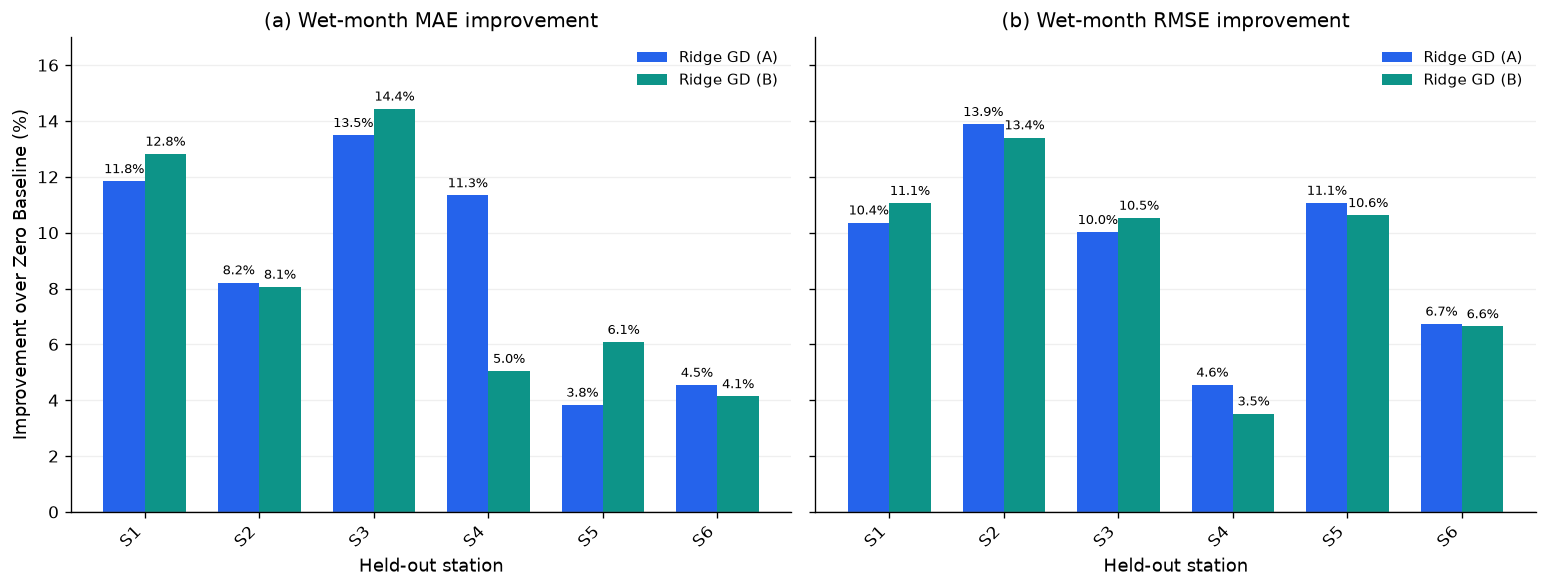

Saved: wet_month_station_improvement


In [ ]:
station_labels = [f"S{i+1}" for i in range(6)]
x = np.arange(6)
width = 0.36

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharey=True
)

comparisons = [
    (wet_mae_comparison, "(a) Wet-month MAE improvement"),
    (wet_rmse_comparison, "(b) Wet-month RMSE improvement")
]

colors = ["#2563EB", "#0D9488"]
models = ["Ridge GD (A)", "Ridge GD (B)"]
columns = ["IMPROVEMENT_A", "IMPROVEMENT_B"]

for ax, (data, title) in zip(axes, comparisons):

    for i, (model, col, color) in enumerate(
        zip(models, columns, colors)
    ):
        positions = x + (i - 0.5) * width

        bars = ax.bar(
            positions,
            data[col],
            width,
            label=model,
            color=color
        )

        ax.bar_label(
            bars,
            fmt="%.1f%%",
            padding=3,
            fontsize=8
        )

    ax.set_title(title, fontsize=12)
    ax.set_xticks(x)

    ax.set_xticklabels(station_labels, rotation=45, ha="right")

    ax.set_xlabel("Held-out station")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)

axes[0].set_ylabel(
    "Improvement over Zero Baseline (%)"
)

axes[0].set_ylim(0, 17)

plt.tight_layout()
plt.show()
save_figure(fig, "wet_month_station_improvement")

Figure X. Percentage improvement in wet-month (a) MAE and (b) RMSE achieved by Ridge Regression with Feature Sets A and B relative to the zero-rainfall baseline under leave-one-station-out evaluation. Positive values indicate lower prediction errors. Stations S1–S6 correspond to the six held-out UAE weather stations. Improvements are calculated separately for each station using observations with positive recorded rainfall.

In [ ]:
def analyze_negative_predictions(predictions_df, model_name):

    y_pred = predictions_df["PREDICTED"].to_numpy(dtype=float)

    negative_mask = y_pred < 0

    negative_count = np.sum(negative_mask)

    negative_percentage = (
        negative_count / len(y_pred)
    ) * 100

    return {
        "MODEL": model_name,
        "TOTAL_PREDICTIONS": len(y_pred),
        "NEGATIVE_COUNT": negative_count,
        "NEGATIVE_PERCENTAGE": negative_percentage,
        "MIN_PREDICTION": np.min(y_pred)
    }


negative_results = pd.DataFrame([
    analyze_negative_predictions(analysis_a, "Ridge GD (A)"),
    analyze_negative_predictions(analysis_b, "Ridge GD (B)")
])

display(negative_results)


,MODEL,TOTAL_PREDICTIONS,NEGATIVE_COUNT,NEGATIVE_PERCENTAGE,MIN_PREDICTION
0,Ridge GD (A),1768,59,3.337104,-1.607754
1,Ridge GD (B),1768,66,3.733032,-1.708161


In [ ]:
# clipping negative predictions to zero

def evaluate_clipping(predictions_df, model_name):

    y_true = predictions_df['ACTUAL'].to_numpy(dtype=float)
    y_pred = predictions_df['PREDICTED'].to_numpy(dtype=float)

    y_pred_clipped = np.maximum(y_pred, 0)

    mae = calculate_mae(y_true, y_pred)
    rmse = calculate_rmse(y_true, y_pred)

    clipped_mae = calculate_mae(y_true, y_pred_clipped)
    clipped_rmse = calculate_rmse(y_true, y_pred_clipped)


    return {
        "MODEL": model_name,
        "MAE": mae,
        "CLIPPED_MAE": clipped_mae,
        "RMSE": rmse,
        "CLIPPED_RMSE": clipped_rmse
    }

clipping_results = pd.DataFrame([
    evaluate_clipping(analysis_a, "Ridge GD (A)"),
    evaluate_clipping(analysis_b, "Ridge GD (B)")
])

display(clipping_results)


,MODEL,MAE,CLIPPED_MAE,RMSE,CLIPPED_RMSE
0,Ridge GD (A),8.794052,8.776877,20.850673,20.849185
1,Ridge GD (B),8.794165,8.772396,20.920101,20.918315


In [ ]:

def negative_predictions_by_station(predictions_df, model_name):

    results = []

    for station, group in predictions_df.groupby("STATION"):

        y_pred = group["PREDICTED"].to_numpy(dtype=float)
        negative_mask = y_pred < 0
        negative_count = np.sum(negative_mask)

        results.append({
            "MODEL": model_name,
            "STATION": station,
            "TOTAL": len(group),
            "NEGATIVE_COUNT": negative_count,
            "NEGATIVE_PERCENTAGE": (
                negative_count / len(group)
            ) * 100
        })

    return pd.DataFrame(results)


negative_a_station = negative_predictions_by_station(
    analysis_a, "Ridge GD (A)"
)

negative_b_station = negative_predictions_by_station(
    analysis_b, "Ridge GD (B)"
)

negative_station_df = pd.concat(
    [negative_a_station, negative_b_station],
    ignore_index=True
)

display(negative_station_df)

assert negative_a_station["NEGATIVE_COUNT"].sum() == 59
assert negative_b_station["NEGATIVE_COUNT"].sum() == 66

print("Station-wise negative prediction counts: PASSED")


,MODEL,STATION,TOTAL,NEGATIVE_COUNT,NEGATIVE_PERCENTAGE
0,Ridge GD (A),41184099999,297,6,2.020202
1,Ridge GD (A),41194099999,313,0,0.000000
2,Ridge GD (A),41196099999,295,0,0.000000
3,Ridge GD (A),41198099999,272,2,0.735294
4,Ridge GD (A),41217099999,302,6,1.986755
5,Ridge GD (A),41218099999,289,45,15.570934
6,Ridge GD (B),41184099999,297,5,1.683502
7,Ridge GD (B),41194099999,313,0,0.000000
8,Ridge GD (B),41196099999,295,0,0.000000
9,Ridge GD (B),41198099999,272,2,0.735294


Station-wise negative prediction counts: PASSED


In [ ]:

def evaluate_clipping_by_station(predictions_df, model_name):

    results = []
    for station, group in predictions_df.groupby("STATION"):

        y_true = group["ACTUAL"].to_numpy(dtype=float)
        y_pred = group["PREDICTED"].to_numpy(dtype=float)

        y_clipped = np.maximum(y_pred, 0)

        original_mae = calculate_mae(y_true, y_pred)
        clipped_mae = calculate_mae(y_true, y_clipped)

        original_rmse = calculate_rmse(y_true, y_pred)
        clipped_rmse = calculate_rmse(y_true, y_clipped)

        results.append({
            "MODEL": model_name,
            "STATION": station,
            "ORIGINAL_MAE": original_mae,
            "CLIPPED_MAE": clipped_mae,
            "ORIGINAL_RMSE": original_rmse,
            "CLIPPED_RMSE": clipped_rmse
        })

    return pd.DataFrame(results)


clipping_station_a = evaluate_clipping_by_station(
    analysis_a, "Ridge GD (A)"
)

clipping_station_b = evaluate_clipping_by_station(
    analysis_b, "Ridge GD (B)"
)

clipping_station_df = pd.concat(
    [clipping_station_a, clipping_station_b],
    ignore_index=True
)

display(clipping_station_df.round(4))


,MODEL,STATION,ORIGINAL_MAE,CLIPPED_MAE,ORIGINAL_RMSE,CLIPPED_RMSE
0,Ridge GD (A),41184099999,9.0291,9.0225,19.0617,19.0588
1,Ridge GD (A),41194099999,7.7270,7.7270,13.6202,13.6202
2,Ridge GD (A),41196099999,9.6374,9.6374,20.0058,20.0058
3,Ridge GD (A),41198099999,12.3220,12.3185,35.5711,35.5711
4,Ridge GD (A),41217099999,7.5125,7.5073,13.5809,13.5798
5,Ridge GD (A),41218099999,6.8660,6.7765,17.1223,17.1155
6,Ridge GD (B),41184099999,9.1413,9.1362,18.9914,18.9878
7,Ridge GD (B),41194099999,7.5815,7.5815,13.6347,13.6347
8,Ridge GD (B),41196099999,9.6622,9.6622,19.9395,19.9395
9,Ridge GD (B),41198099999,12.8178,12.8132,35.9458,35.9458


In [ ]:
# training-only mean climatology baseline

climatology_results = []

for test_station, train_df, test_df in manual_loso(df):
    y_train = train_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
    y_test = test_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

    train_mean = np.mean(y_train)
    y_pred = np.full(len(y_test), train_mean)

    mae = calculate_mae(y_test, y_pred)
    rmse = calculate_rmse(y_test, y_pred)

    climatology_results.append({
        "STATION": test_station,
        "TRAIN_MEAN": train_mean,
        "TEST_ROWS": len(y_test),
        "MAE": mae,
        "RMSE": rmse
    })

climatology_df = pd.DataFrame(climatology_results)
display(climatology_df)


,STATION,TRAIN_MEAN,TEST_ROWS,MAE,RMSE
0,41184099999,5.663976,297,10.460477,19.506661
1,41194099999,6.290821,313,8.323441,14.057633
2,41196099999,5.646629,295,10.313401,20.318335
3,41198099999,5.456246,272,11.505680,35.801997
4,41217099999,6.529325,302,8.071031,13.685127
5,41218099999,6.435010,289,8.170164,17.303553


In [ ]:
zero_summary = baseline_results_df[
    ["STATION", "MAE", "RMSE"]
].copy()
zero_summary["MODEL"] = "Zero Baseline"

mean_summary = climatology_df[
    ["STATION", "MAE", "RMSE"]
].copy()
mean_summary["MODEL"] = "Mean Climatology"

ridge_a_summary = results_a[
    ["STATION", "MAE", "RMSE"]
].copy()
ridge_a_summary["MODEL"] = "Ridge GD (A)"

ridge_b_summary = results_b[
    ["STATION", "MAE", "RMSE"]
].copy()
ridge_b_summary["MODEL"] = "Ridge GD (B)"

all_model_results_df = pd.concat(
    [
        zero_summary,
        mean_summary,
        ridge_a_summary,
        ridge_b_summary
    ],
    ignore_index=True
)

model_summary_df = all_model_results_df.groupby(
    "MODEL",
    as_index=False
)[["MAE", "RMSE"]].mean()

model_summary_df = model_summary_df.sort_values(
    by="MAE",
    ascending=True
)

display(model_summary_df.round(4))


,MODEL,MAE,RMSE
3,Zero Baseline,6.0550,20.8769
1,Ridge GD (A),8.8490,19.8270
2,Ridge GD (B),8.8572,19.8566
0,Mean Climatology,9.4740,20.1122


In [ ]:
# hyperparameter tuning for Ridge Regression

lambda_values = np.array([0.001, 0.01, 0.1, 1.0, 10.0])

n_lambda = len(lambda_values)

outer_station, outer_train_df, outer_test_df = next(manual_loso(df))
print("Outer held-out station:", outer_station)

inner_fold_results = []

for inner_station, inner_train_df, inner_val_df in manual_loso(outer_train_df):
    n_train_stations = inner_train_df["STATION"].nunique()
    n_val_stations = inner_val_df["STATION"].nunique()
    assert set(inner_train_df["STATION"]).isdisjoint(
        set(inner_val_df["STATION"])
    )

    inner_fold_results.append({
        "INNER_VAL_STATION": inner_station,
        "TRAIN_STATIONS": n_train_stations,
        "VAL_STATIONS": n_val_stations,
        "TRAIN_ROWS": len(inner_train_df),
        "VAL_ROWS": len(inner_val_df)
    })

inner_folds_df = pd.DataFrame(inner_fold_results)
display(inner_folds_df)

Outer held-out station: 41184099999


,INNER_VAL_STATION,TRAIN_STATIONS,VAL_STATIONS,TRAIN_ROWS,VAL_ROWS
0,41194099999,4,1,1158,313
1,41196099999,4,1,1176,295
2,41198099999,4,1,1199,272
3,41217099999,4,1,1169,302
4,41218099999,4,1,1182,289


In [ ]:
features = [
    'TEMP_MEAN',
    'DEWP_MEAN',
    'WDSP_MEAN',
    'TEMP_MIN_MEAN',
    'TEMP_MAX_MEAN',
]
inner_lambda_results = []

for lambda_value in lambda_values:

    for inner_station, inner_train_df, inner_val_df in manual_loso(outer_train_df):

        X_train = inner_train_df[features].to_numpy(dtype=float)
        X_val = inner_val_df[features].to_numpy(dtype=float)

        y_train = inner_train_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
        y_val = inner_val_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

        mean, std = fit_standardizer(X_train)
        X_train_scaled = transform_standardizer(X_train, mean, std)
        X_val_scaled = transform_standardizer(X_val, mean, std)

        model = RidgeRegressionGD(
            learning_rate=0.01,
            iterations=3000,
            lambda_=lambda_value
        )

        model.fit(X_train_scaled, y_train)
        y_pred_val = model.predict(X_val_scaled)

        mae_val = calculate_mae(y_val, y_pred_val)
        rmse_val = calculate_rmse(y_val, y_pred_val)

        inner_lambda_results.append({
            "LAMBDA": lambda_value,
            "INNER_VAL_STATION": inner_station,
            "MAE": mae_val,
            "RMSE": rmse_val
        })

inner_lambda_df = pd.DataFrame(inner_lambda_results)
display(inner_lambda_df)


,LAMBDA,INNER_VAL_STATION,MAE,RMSE
0,0.001,41194099999,7.790609,13.622031
1,0.001,41196099999,8.694811,20.567443
2,0.001,41198099999,11.795128,35.537892
3,0.001,41217099999,7.721452,13.597025
4,0.001,41218099999,6.925807,17.097808
5,0.010,41194099999,7.790583,13.622029
6,0.010,41196099999,8.694768,20.567395
7,0.010,41198099999,11.795069,35.537895
8,0.010,41217099999,7.721450,13.597022
9,0.010,41218099999,6.925809,17.097802


In [ ]:
lambda_summary_df = inner_lambda_df.groupby(
    'LAMBDA',
    as_index=False
)[['MAE', 'RMSE']].mean()

lambda_summary_df = lambda_summary_df.sort_values(
    by='RMSE',
    ascending=True
)

display(lambda_summary_df.round(6))

best_lambda = lambda_summary_df.iloc[0]['LAMBDA']
best_val_rmse = lambda_summary_df.iloc[0]['RMSE']

print(f"Best lambda: {best_lambda}")
print(f"Best validation RMSE: {best_val_rmse:.6f}")



,LAMBDA,MAE,RMSE
4,10.000,8.561651,20.072843
3,1.000,8.582889,20.083190
2,0.100,8.585289,20.084315
1,0.010,8.585536,20.084428
0,0.001,8.585561,20.084440


Best lambda: 10.0
Best validation RMSE: 20.072843


In [ ]:
# final model

X_train = outer_train_df[features].to_numpy(dtype=float)
X_test = outer_test_df[features].to_numpy(dtype=float)

y_train = outer_train_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
y_test = outer_test_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

mean, std = fit_standardizer(X_train)
X_train_scaled = transform_standardizer(X_train, mean, std)
X_test_scaled = transform_standardizer(X_test, mean, std)

tuned_model = RidgeRegressionGD(
    learning_rate=0.01,
    iterations=3000,
    lambda_=best_lambda
)

tuned_model.fit(X_train_scaled, y_train)
y_pred = tuned_model.predict(X_test_scaled)

outer_mae = calculate_mae(y_test, y_pred)
outer_rmse = calculate_rmse(y_test, y_pred)

print("Outer held-out station:", outer_station)
print("Best lambda:", best_lambda)
print(f"Outer MAE: {outer_mae:.4f}")
print(f"Outer RMSE: {outer_rmse:.4f}")


Outer held-out station: 41184099999
Best lambda: 10.0
Outer MAE: 9.0720
Outer RMSE: 19.0523


In [ ]:
def tune_lambda_inner_loso(outer_train_df, features, lambda_values):

    tuning_results = []

    for lambda_value in lambda_values:
        for inner_station, inner_train_df, inner_val_df in manual_loso(outer_train_df):
            X_train = inner_train_df[features].to_numpy(dtype=float)
            X_val = inner_val_df[features].to_numpy(dtype=float)

            y_train = inner_train_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
            y_val = inner_val_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

            mean, std = fit_standardizer(X_train)
            X_train_scaled = transform_standardizer(X_train, mean, std)
            X_val_scaled = transform_standardizer(X_val, mean, std)

            model = RidgeRegressionGD(
                learning_rate=0.01,
                iterations=3000,
                lambda_=lambda_value
            )

            model.fit(X_train_scaled, y_train)
            y_pred_val = model.predict(X_val_scaled)

            rmse_val = calculate_rmse(y_val, y_pred_val)

            tuning_results.append({
                "LAMBDA": lambda_value,
                "INNER_VAL_STATION": inner_station,
                "RMSE": rmse_val
            })

    tuning_df = pd.DataFrame(tuning_results)

    summary_df = (
        tuning_df.groupby('LAMBDA', as_index=False)[['RMSE']].mean()
        .sort_values(by='RMSE', ascending=True)
    )

    best_lambda = summary_df.iloc[0]['LAMBDA']
    return best_lambda, summary_df

In [ ]:
results = []
nested_pred = []

for outer_station, outer_train_df, outer_test_df in manual_loso(df):
    selected_lambda, summary_df = tune_lambda_inner_loso(
        outer_train_df, features, lambda_values
    )

    X_train = outer_train_df[features].to_numpy(dtype=float)
    X_test = outer_test_df[features].to_numpy(dtype=float)

    y_train = outer_train_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)
    y_test = outer_test_df['TARGET_NEXT_MONTH'].to_numpy(dtype=float)

    mean, std = fit_standardizer(X_train)
    X_train_scaled = transform_standardizer(X_train, mean, std)
    X_test_scaled = transform_standardizer(X_test, mean, std)

    model = RidgeRegressionGD(
        learning_rate=0.01,
        iterations=3000,
        lambda_=selected_lambda
    )
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    for actual, predicted in zip(y_test, y_pred):

        nested_pred.append({
            'STATION': outer_station,
            'ACTUAL': actual,
            'PREDICTED': predicted
        })

    mae_test = calculate_mae(y_test, y_pred)
    rmse_test = calculate_rmse(y_test, y_pred)
    results.append({
        "STATION": outer_station,
        "SELECTED_LAMBDA": selected_lambda,
        "TEST_ROWS": len(outer_test_df),
        "MAE": mae_test,
        "RMSE": rmse_test
    })

results_df = pd.DataFrame(results)
display(results_df)

nested_pred_df = pd.DataFrame(nested_pred)
print("Nested predictions saved:", len(nested_pred_df))

,STATION,SELECTED_LAMBDA,TEST_ROWS,MAE,RMSE
0,41184099999,10.0,297,9.072027,19.052306
1,41194099999,10.0,313,7.707404,13.618968
2,41196099999,10.0,295,9.656984,20.005212
3,41198099999,10.0,272,12.244549,35.569769
4,41217099999,10.0,302,7.517288,13.579749
5,41218099999,10.0,289,6.862772,17.115797


Nested predictions saved: 1768


In [ ]:

print(
    "Mean Nested LOSO MAE:",
    round(results_df["MAE"].mean(), 4)
)

print(
    "Mean Nested LOSO RMSE:",
    round(results_df["RMSE"].mean(), 4)
)

print("\nSelected Lambda frequencies:")
print(results_df["SELECTED_LAMBDA"].value_counts())


Mean Nested LOSO MAE: 8.8435
Mean Nested LOSO RMSE: 19.8236

Selected Lambda frequencies:
SELECTED_LAMBDA
10.0    6
Name: count, dtype: int64


In [ ]:
final_comparison_df = model_summary_df.copy()

tuned_mae = results_df["MAE"].mean()
tuned_rmse = results_df["RMSE"].mean()

tuned_rows = pd.DataFrame([{
    'MODEL' : 'Tuned Ridge GD (A)',
    'MAE': tuned_mae,
    'RMSE': tuned_rmse
}])

final_comparison_df = pd.concat(
    [final_comparison_df, tuned_rows],
    ignore_index=True
)
final_comparison_df = final_comparison_df.sort_values(
    by='RMSE',
    ascending=True
)

display(final_comparison_df.round(4))

,MODEL,MAE,RMSE
4,Tuned Ridge GD (A),8.8435,19.8236
1,Ridge GD (A),8.8490,19.8270
2,Ridge GD (B),8.8572,19.8566
3,Mean Climatology,9.4740,20.1122
0,Zero Baseline,6.0550,20.8769


In [ ]:
baseline_station_df = baseline_results_df[
    ['STATION','RMSE']
].rename(columns={'RMSE':'BASELINE_RMSE'})

tuned_station_df = results_df[
    ['STATION','RMSE']
].rename(columns={'RMSE':'TUNED_RMSE'})

station_comparison_df = pd.merge(
    baseline_station_df,
    tuned_station_df,
    on='STATION',
    how='inner',
    validate='one_to_one'
)

station_comparison_df['IMPROVEMENT'] = (
    (station_comparison_df['BASELINE_RMSE'] - station_comparison_df['TUNED_RMSE'])
    / station_comparison_df['BASELINE_RMSE']
) * 100

display(station_comparison_df.round(4))


,STATION,BASELINE_RMSE,TUNED_RMSE,IMPROVEMENT
0,41184099999,20.8652,19.0523,8.6888
1,41194099999,14.7186,13.6190,7.4712
2,41196099999,21.6505,20.0052,7.5994
3,41198099999,36.7456,35.5698,3.1999
4,41217099999,13.7685,13.5797,1.3709
5,41218099999,17.5128,17.1158,2.2671


In [ ]:
station_rainfall_df = (
    df.groupby('STATION')['TARGET_NEXT_MONTH']
    .agg(
        N='count',
        MEAN_RAINFALL='mean',
        MEDIAN_RAINFALL = 'median',
        MAX_RAINFALL = 'max',
        STD_RAINFALL = 'std'
    )
    .reset_index()
)

wet_percentage = (
    df.assign(
        IS_WET = df['TARGET_NEXT_MONTH'] > 0
    )
    .groupby("STATION")['IS_WET'].mean() * 100
)

station_rainfall_df['WET_MONTH_PCT'] = (
    station_rainfall_df['STATION'].map(wet_percentage)
)

station_difficulty_df = pd.merge(
    station_rainfall_df,
    results_df[['STATION', 'RMSE']],
    on= 'STATION',
    how='inner',
    validate='one_to_one'
)

station_difficulty_df = station_difficulty_df.sort_values(
    by = 'RMSE',
    ascending= False
)

display(station_difficulty_df.round(3))

,STATION,N,MEAN_RAINFALL,MEDIAN_RAINFALL,MAX_RAINFALL,STD_RAINFALL,WET_MONTH_PCT,RMSE
3,41198099999,272,9.001,0.0,475.488,35.692,37.868,35.570
2,41196099999,295,7.774,0.0,147.320,20.241,37.627,20.005
0,41184099999,297,7.674,0.0,119.888,19.436,33.333,19.052
5,41218099999,289,3.784,0.0,193.040,17.129,28.720,17.116
1,41194099999,313,4.657,0.0,112.014,13.985,35.144,13.619
4,41217099999,302,3.440,0.0,132.080,13.354,22.848,13.580


In [178]:
hardest_station = 41198099999

hardest_df = nested_pred_df[
    nested_pred_df['STATION'] == hardest_station
].copy()

hardest_df['ABS_ERROR'] = np.abs(
    hardest_df['ACTUAL'] - hardest_df['PREDICTED']
)

hardest_df["HIGH_RAINFALL"] = (
    hardest_df["ACTUAL"] >= 50
)

n_high = hardest_df["HIGH_RAINFALL"].sum()

print("Total observations:", len(hardest_df))
print("High-rainfall months:", n_high)

display(
    hardest_df.sort_values(
        "ACTUAL", ascending=False
    ).head(10).round(3)
)


Total observations: 272
High-rainfall months: 13


,STATION,ACTUAL,PREDICTED,ABS_ERROR,HIGH_RAINFALL
1061,41198099999,475.488,7.361,468.127,True
1159,41198099999,220.218,6.021,214.197,True
986,41198099999,188.214,9.057,179.157,True
1165,41198099999,80.518,10.043,70.475,True
984,41198099999,56.134,8.843,47.291,True
1087,41198099999,55.626,7.649,47.977,True
1007,41198099999,55.372,9.881,45.491,True
1073,41198099999,53.594,9.433,44.161,True
1014,41198099999,51.562,7.369,44.193,True
928,41198099999,51.054,9.295,41.759,True


In [190]:
hardest_df['SQUARED_ERROR'] = (
    hardest_df['ACTUAL'] - hardest_df['PREDICTED']
) ** 2

total_sse = hardest_df['SQUARED_ERROR'].sum()

high_sse = hardest_df.loc[
    hardest_df['HIGH_RAINFALL'],
    'SQUARED_ERROR'
].sum()

high_sse_pct = (
    high_sse / total_sse
) * 100

print("Total SSE:", round(total_sse, 2))
print("High-rainfall SSE:", round(high_sse, 2))
print("High-rainfall contribution:", round(high_sse_pct, 2), "%")

Total SSE: 344136.7
High-rainfall SSE: 320031.94
High-rainfall contribution: 93.0 %


In [193]:
reconstructed_rmse = np.sqrt(
    total_sse / len(hardest_df)
)

print("Reconstructed RMSE:", round(reconstructed_rmse, 4))



Reconstructed RMSE: 35.5698


At the most challenging held-out station (41198099999), only 13 of 272 observations (4.78%) recorded monthly rainfall of at least 50 mm. However, these observations accounted for approximately 93% of the total squared prediction error. This indicates that the station's elevated RMSE was largely driven by substantial underestimation during high-rainfall months, highlighting a limitation of the Ridge model in predicting extreme rainfall magnitudes at an unseen station.

In [198]:
worst_row = hardest_df.loc[hardest_df['SQUARED_ERROR'].idxmax()]

worst_contribution = (worst_row['SQUARED_ERROR']/ total_sse) * 100

print("Actual rainfall:", round(worst_row["ACTUAL"], 3))
print("Predicted rainfall:", round(worst_row["PREDICTED"], 3))
print("Squared error:", round(worst_row["SQUARED_ERROR"], 2))
print("Contribution to total SSE:", round(worst_contribution, 2), "%")

Actual rainfall: 475.488
Predicted rainfall: 7.361
Squared error: 219142.95
Contribution to total SSE: 63.68 %


A single high-rainfall observation (475.488 mm) accounted for 63.68% of the total squared prediction error at the most challenging held-out station. The Ridge model substantially underestimated this event, predicting only 7.361 mm. This finding demonstrates the sensitivity of RMSE to rare high-magnitude rainfall events and motivates a complementary evaluation of model performance under typical and extreme rainfall conditions.

In [200]:
rmse_all = np.sqrt(hardest_df['SQUARED_ERROR'].mean())
worst_idx = hardest_df['SQUARED_ERROR'].idxmax()

without_worst_df = hardest_df.drop(index=worst_idx)
rmse_without_worst = np.sqrt(without_worst_df['SQUARED_ERROR'].mean())
reduction_pct = ((rmse_all - rmse_without_worst) / rmse_all) * 100

print("Original RMSE:", round(rmse_all, 4))
print("RMSE without worst event:", round(rmse_without_worst, 4))
print("RMSE reduction:", round(reduction_pct, 2), "%")

Original RMSE: 35.5698
RMSE without worst event: 21.4763
RMSE reduction: 39.62 %


A sensitivity analysis was conducted for the most challenging held-out station (41198099999). Excluding the single observation with the largest squared prediction error reduced RMSE from 35.57 mm to 21.48 mm, corresponding to a 39.62% reduction. This observation alone accounted for 63.68% of the station's total squared error. These findings demonstrate that station-level RMSE is highly sensitive to rare, high-magnitude rainfall events. The original RMSE was retained for the primary evaluation, while the exclusion analysis was used solely to assess metric sensitivity.

In [202]:
# Does ridge perform better on dry, moderate or high rainfall months?

conditions = [
    hardest_df['ACTUAL'] == 0,
    (hardest_df['ACTUAL'] > 0) & (hardest_df['ACTUAL'] < 50),
    hardest_df['ACTUAL'] >=50
]

labels = ['Dry', 'Moderate', 'High']

hardest_df['RAINFALL_CATEGORY'] = np.select(
    conditions, labels, default='Unknown'
)

category_results_df = (hardest_df.groupby("RAINFALL_CATEGORY")
                       .agg(
                           N=("ACTUAL", "count"),
                           MAE=("ABS_ERROR", "mean"),
                           MSE=("SQUARED_ERROR", 'mean')
                       ).reset_index())

category_results_df['RMSE'] = np.sqrt(
    category_results_df['MSE']
)
display(category_results_df.round(3))

,RAINFALL_CATEGORY,N,MAE,MSE,RMSE
0,Dry,169,6.862,54.689,7.395
1,High,13,102.565,24617.841,156.901
2,Moderate,90,9.305,165.138,12.851


Rainfall-stratified evaluation at the most challenging held-out station revealed substantial differences in prediction accuracy. The Ridge model achieved RMSE values of 7.40 mm for dry months, 12.85 mm for moderate-rainfall months, and 156.90 mm for high-rainfall months (≥50 mm). Although high-rainfall months represented only 4.78% of observations, they accounted for approximately 93% of total squared prediction error. These findings indicate substantial underestimation of high rainfall magnitudes and demonstrate the importance of evaluating cross-station generalization across different rainfall conditions.

In [206]:
hardest_df['ZERO_PRED'] = 0.0

hardest_df['ZERO_ABS_ERROR'] = np.abs(hardest_df['ACTUAL'] - hardest_df['ZERO_PRED'])
hardest_df['ZERO_SQUARED_ERROR'] = (hardest_df['ACTUAL'] - hardest_df['ZERO_PRED']) ** 2

zero_category_df = (
    hardest_df.groupby("RAINFALL_CATEGORY")
    .agg(
        ZERO_MAE=("ZERO_ABS_ERROR", "mean"),
        ZERO_MSE=("ZERO_SQUARED_ERROR", "mean")
    )
    .reset_index()
)

zero_category_df["ZERO_RMSE"] = np.sqrt(
    zero_category_df["ZERO_MSE"]
)

display(zero_category_df.round(3))

,RAINFALL_CATEGORY,ZERO_MAE,ZERO_MSE,ZERO_RMSE
0,Dry,0.000,0.000,0.000
1,High,110.685,26273.491,162.091
2,Moderate,11.216,285.657,16.901


In [207]:

comparison_category_df = pd.merge(
    category_results_df[
        ["RAINFALL_CATEGORY", "N", "MAE", "RMSE"]
    ],
    zero_category_df[
        ["RAINFALL_CATEGORY", "ZERO_MAE", "ZERO_RMSE"]
    ],
    on="RAINFALL_CATEGORY",
    validate="one_to_one"
)

comparison_category_df["RMSE_IMPROVEMENT_PCT"] = (
    (
        comparison_category_df["ZERO_RMSE"]
        - comparison_category_df["RMSE"]
    )
    / comparison_category_df["ZERO_RMSE"].replace(0, np.nan)
) * 100

display(comparison_category_df.round(3))


,RAINFALL_CATEGORY,N,MAE,RMSE,ZERO_MAE,ZERO_RMSE,RMSE_IMPROVEMENT_PCT
0,Dry,169,6.862,7.395,0.000,0.000,NaN
1,High,13,102.565,156.901,110.685,162.091,3.202
2,Moderate,90,9.305,12.851,11.216,16.901,23.967


At station 41198099999, the tuned Ridge model reduced RMSE relative to the zero-rainfall baseline by 23.97% for moderate-rainfall months and 3.20% for high-rainfall months. Conversely, the zero baseline achieved perfect predictions for dry months. These results suggest that Ridge captures useful predictive information for moderate rainfall but provides limited improvements when estimating high rainfall magnitudes.

In [208]:
all_station_df = nested_pred_df.copy()

all_station_df['STATION'] = (all_station_df['STATION'].astype(str))
all_station_df['SQUARED_ERROR'] = (all_station_df['ACTUAL'] - all_station_df['PREDICTED']) ** 2
all_station_df['HIGH_RAINFALL'] = (all_station_df['ACTUAL'] >= 50)

station_total_sse = (all_station_df.groupby("STATION")["SQUARED_ERROR"].sum())
station_high_sse = (all_station_df[all_station_df['HIGH_RAINFALL']].groupby("STATION")['SQUARED_ERROR'].sum())

station_extreme_df = pd.DataFrame({
    'TOTAL_SSE': station_total_sse,
    'HIGH_SSE': station_high_sse
}).fillna(0)

station_extreme_df['HIGH_SSE_PCT'] = (
    station_extreme_df['HIGH_SSE'] / station_extreme_df['TOTAL_SSE']
) * 100

display(station_extreme_df.round(2))

,TOTAL_SSE,HIGH_SSE,HIGH_SSE_PCT
STATION,,,
41184099999,107808.13,89194.81,82.73
41194099999,58054.08,35361.99,60.91
41196099999,118061.51,98157.76,83.14
41198099999,344136.70,320031.94,93.00
41217099999,55691.69,37053.47,66.53
41218099999,84662.70,69786.45,82.43


Across all six held-out stations, months recording at least 50 mm of rainfall accounted for 60.91%–93.00% of the total squared prediction error, with a mean station-level contribution of 78.12%. This consistent concentration of squared errors suggests that high-rainfall observations substantially influence the evaluation of cross-station predictive performance. However, the error contribution alone does not establish whether the Ridge model performs better or worse than a baseline during these events.

In [210]:

station_high_counts = (
    all_station_df.groupby("STATION")
    .agg(
        TOTAL_MONTHS=("ACTUAL", "count"),
        HIGH_MONTHS=("HIGH_RAINFALL", "sum")
    )
    .reset_index()
)

station_high_counts["HIGH_MONTH_PCT"] = (
    station_high_counts["HIGH_MONTHS"]
    / station_high_counts["TOTAL_MONTHS"]
) * 100

station_high_summary_df = pd.merge(
    station_high_counts,
    station_extreme_df.reset_index()[
        ["STATION", "HIGH_SSE_PCT"]
    ],
    on="STATION",
    validate="one_to_one"
)

display(station_high_summary_df.round(2))


,STATION,TOTAL_MONTHS,HIGH_MONTHS,HIGH_MONTH_PCT,HIGH_SSE_PCT
0,41184099999,297,19,6.40,82.73
1,41194099999,313,5,1.60,60.91
2,41196099999,295,16,5.42,83.14
3,41198099999,272,13,4.78,93.00
4,41217099999,302,7,2.32,66.53
5,41218099999,289,4,1.38,82.43


Across the six held-out stations, only 64 of 1,768 observations (3.62%) recorded rainfall of at least 50 mm. Despite their low frequency, these observations accounted for between 60.91% and 93.00% of the total squared prediction error at individual stations. This finding demonstrates that rare high-rainfall observations disproportionately influence RMSE-based evaluation across the study stations.

In [214]:
high_df = all_station_df[all_station_df["HIGH_RAINFALL"]].copy()

high_df["ZERO_SQUARED_ERROR"] = (high_df["ACTUAL"] - 0) ** 2

high_comparison_df = (
    high_df.groupby("STATION")
    .agg(
        N=("ACTUAL", "count"),
        RIDGE_MSE=("SQUARED_ERROR", "mean"),
        ZERO_MSE=("ZERO_SQUARED_ERROR", "mean")
    )
    .reset_index()
)

high_comparison_df["RIDGE_RMSE"] = np.sqrt(high_comparison_df["RIDGE_MSE"])
high_comparison_df["ZERO_RMSE"] = np.sqrt(high_comparison_df["ZERO_MSE"])

high_comparison_df["IMPROVEMENT_PCT"] = (
    (high_comparison_df["ZERO_RMSE"]
     - high_comparison_df["RIDGE_RMSE"])
    / high_comparison_df["ZERO_RMSE"]
) * 100

display(
    high_comparison_df[
        ["STATION", "N", "RIDGE_RMSE",
         "ZERO_RMSE", "IMPROVEMENT_PCT"]
    ].round(3)
)


,STATION,N,RIDGE_RMSE,ZERO_RMSE,IMPROVEMENT_PCT
0,41184099999,19,68.516,74.734,8.320
1,41194099999,5,84.098,92.845,9.421
2,41196099999,16,78.325,84.629,7.448
3,41198099999,13,156.901,162.091,3.202
4,41217099999,7,72.755,81.563,10.798
5,41218099999,4,132.086,138.801,4.838


During high-rainfall months (≥50 mm), the tuned Ridge model achieved lower RMSE than the zero-rainfall baseline at all six held-out stations, with relative improvements ranging from approximately 3.20% to 10.80%. Nevertheless, absolute RMSE remained high, indicating that the model provided limited improvements in predicting high rainfall magnitudes. These findings suggest that extreme rainfall estimation remains a challenge for cross-station generalization

In [216]:
moderate_df = all_station_df[
    (all_station_df["ACTUAL"] > 0) &
    (all_station_df["ACTUAL"] < 50)
].copy()

moderate_df["ZERO_SQUARED_ERROR"] = (moderate_df["ACTUAL"] - 0) ** 2

moderate_comparison_df = (
    moderate_df.groupby("STATION")
    .agg(
        N=("ACTUAL", "count"),
        RIDGE_MSE=("SQUARED_ERROR", "mean"),
        ZERO_MSE=("ZERO_SQUARED_ERROR", "mean")
    )
    .reset_index()
)

moderate_comparison_df["RIDGE_RMSE"] = np.sqrt(moderate_comparison_df["RIDGE_MSE"])

moderate_comparison_df["ZERO_RMSE"] = np.sqrt(moderate_comparison_df["ZERO_MSE"])

moderate_comparison_df["IMPROVEMENT_PCT"] = (
    (
        moderate_comparison_df["ZERO_RMSE"]
        - moderate_comparison_df["RIDGE_RMSE"]
    )
    / moderate_comparison_df["ZERO_RMSE"]
) * 100

display(
    moderate_comparison_df[
        ["STATION", "N", "RIDGE_RMSE",
         "ZERO_RMSE", "IMPROVEMENT_PCT"]
    ].round(3)
)


,STATION,N,RIDGE_RMSE,ZERO_RMSE,IMPROVEMENT_PCT
0,41184099999,80,13.466,17.024,20.900
1,41194099999,105,11.944,15.340,22.136
2,41196099999,95,12.036,15.791,23.779
3,41198099999,90,12.851,16.901,23.967
4,41217099999,62,11.520,13.127,12.239
5,41218099999,79,9.569,12.103,20.941


The tuned Ridge model consistently outperformed the zero-rainfall baseline during moderate-rainfall months across all six held-out stations. The mean station-level RMSE improvement was 20.66% for moderate rainfall, compared with 7.34% for high rainfall. This suggests that the model extracts more useful predictive information relative to the baseline for moderate rainfall, while its relative benefit is smaller during high-rainfall events.

In [220]:
rainfall_comparison_df = pd.merge(
    moderate_comparison_df[
        ["STATION", "IMPROVEMENT_PCT"]
    ].rename(columns={
        "IMPROVEMENT_PCT": "MODERATE_IMPROVEMENT"
    }),

    high_comparison_df[
        ["STATION", "IMPROVEMENT_PCT"]
    ].rename(columns={
        "IMPROVEMENT_PCT": "HIGH_IMPROVEMENT"
    }),

    on="STATION",
    validate="one_to_one"
)

# TODO 2: Calculate the difference in percentage points
rainfall_comparison_df["IMPROVEMENT_GAP_PP"] = (
    rainfall_comparison_df["MODERATE_IMPROVEMENT"]
    - rainfall_comparison_df["HIGH_IMPROVEMENT"]
)

display(rainfall_comparison_df.round(3))


,STATION,MODERATE_IMPROVEMENT,HIGH_IMPROVEMENT,IMPROVEMENT_GAP_PP
0,41184099999,20.900,8.320,12.580
1,41194099999,22.136,9.421,12.714
2,41196099999,23.779,7.448,16.331
3,41198099999,23.967,3.202,20.765
4,41217099999,12.239,10.798,1.441
5,41218099999,20.941,4.838,16.103


Across all six held-out stations, the tuned Ridge model demonstrated larger relative RMSE reductions over the zero-rainfall baseline for moderate-rainfall months than for high-rainfall months. The mean difference was 13.32 percentage points. Combined with the disproportionate contribution of rare high-rainfall observations to squared prediction error, these results highlight the challenge of accurately estimating high rainfall magnitudes when generalizing to unseen stations.